# Serie I · Campo — 03. Modelo supervisado: azúcar por acre de una variedad en una finca

**Pregunta 2 de la prueba:** construir un modelo que estime el azúcar por acre de una variedad en una localidad, útil
para planificar la siguiente zafra; comparar al menos 3 algoritmos (uno interpretable) y validar como se usaría en la
realidad.

**Cómo se usaría.** Al cerrar la zafra del año *t − 1*, la Gerencia planifica la zafra *t*: cuánta azúcar esperar de
cada lote y qué variedad poner en cada finca. El modelo solo puede usar lo que se sabe en ese momento.

**Alcance (dos escenarios):**

| Escenario | Situación real | Qué sabe el modelo | Validación |
|---|---|---|---|
| **1** | Variedad conocida, finca conocida | historia de la variedad, historia de la finca, cosecha del año pasado del mismo lote | entrenar con años < *t*, predecir *t* (2013 → 2021) |
| **2** | Variedad conocida, **finca nueva** | historia de la variedad en *otras* fincas | lo mismo, pero borrando la finca de toda la historia |

El escenario 3 (variedad nueva, solo con datos de etapas 3-4) queda fuera; el README explica cómo se abordaría.

**Decisiones heredadas (bitácora D1-D21):** solo etapa 5; T_SPACRE en lb/acre; testigos núcleo = 4 variedades
presentes los 12 años; cada parcela = promedio de sus repeticiones.

In [1]:
import sys, json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor
warnings.filterwarnings("ignore", category=RuntimeWarning)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from campo_data import load_raw, clean
from campo_economia import CORE_CHECKS
from campo_modelo import (preparar, historia, variables, tabla_asof, metricas, bootstrap_pareado,
                          RIDGE_E1, RIDGE_E2, TREE_E1, TREE_E2, LAMBDA_A, LAMBDA_B, LAMBDA_LOC)

FIG = ROOT / "outputs" / "figures"; TAB = ROOT / "outputs" / "tables"; MOD = ROOT / "outputs" / "models"
for p in (FIG, TAB, MOD): p.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)

AZUL, NARANJA, AQUA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#9a9993"
TINTA, TINTA2, REJILLA = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": REJILLA, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": TINTA, "font.size": 10,
})
def guardar(fig, nombre):
    fig.tight_layout(); fig.savefig(FIG / nombre, bbox_inches="tight"); plt.show()

SEED = 20261019
ANIOS = list(range(2011, 2022))     # años con al menos un año de historia previa (2010 solo es historia)
PRUEBA = list(range(2013, 2022))    # años que se predicen: el primero se entrena con 2011-2012

In [2]:
df, _ = clean(load_raw(ROOT / "data" / "raw" / "All_Genotypes_2010_onwards.csv"))
plot = (df.groupby(["TRIAL","STAGE","LOC","PLANT_YEAR","ENV","CLONE","CROP","YEAR"], as_index=False)
          [["T_SPACRE","TCA","TRS_TON"]].mean())          # promedio de repeticiones = parcela
s5 = plot[plot["STAGE"] == 5].reset_index(drop=True)
P = preparar(s5)   # + rel_sugar (vs testigos del mismo ensayo y corte) + datos del corte anterior del mismo lote
print(f"Etapa 5: {len(P):,} parcelas, {P['TRIAL'].nunique()} ensayos, {P['CLONE'].nunique()} variedades, "
      f"{P['LOC'].nunique()} fincas, {P['YEAR'].min()}-{P['YEAR'].max()}")

Etapa 5: 4,708 parcelas, 160 ensayos, 40 variedades, 14 fincas, 2010-2021


## 1. Cómo se valida: igual que como se usaría

Un *k-fold* aleatorio mezclaría años: el modelo vería parcelas de 2019 al predecir 2018 y aprendería el clima de ese
año a través de los vecinos del mismo campo. Daría un error optimista que nunca se repetiría en la práctica.

- **Escenario 1 — ventana creciente por año (*forward chaining*).** Para predecir *t* se entrena con todo lo anterior
  a *t*. Nueve pruebas: 2013, 2014, …, 2021.
- **Escenario 2 — finca nueva.** Igual que el anterior, pero la finca que se predice se **borra de toda la historia**:
  no aporta filas de entrenamiento, ni su nivel, ni sus resultados con otras variedades. 14 fincas × 9 años.

Además, **cada fila se describe con variables "as-of"**: la historia de la variedad y de la finca se calcula solo con
años anteriores al de esa fila, también en las filas de entrenamiento.

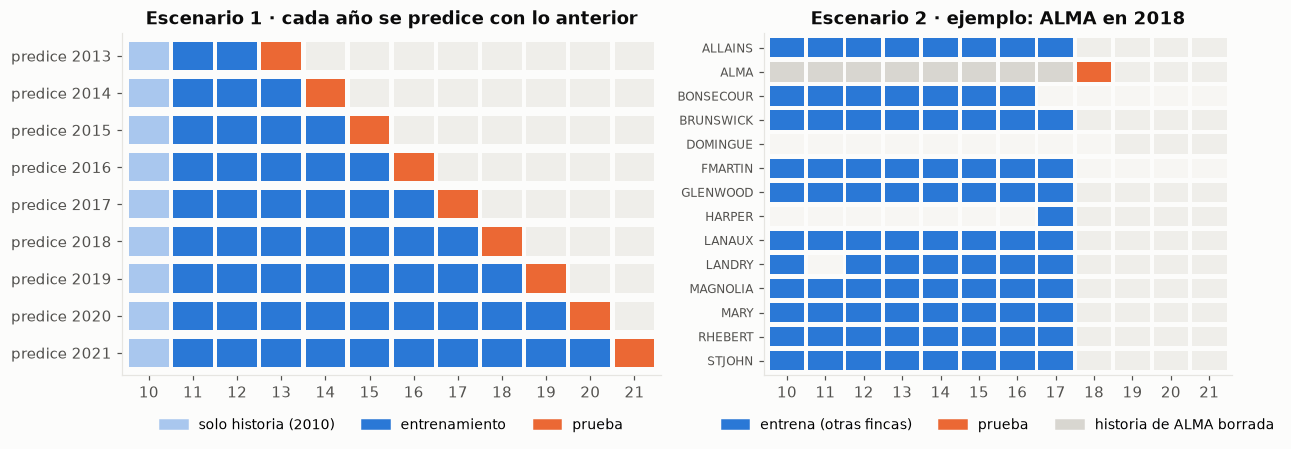

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.15, 1]})
anios = list(range(2010, 2022))
ax = axes[0]
for i, t in enumerate(PRUEBA):
    for a in anios:
        c = AZUL if a < t else (NARANJA if a == t else "#efeeea")
        if a == 2010 and t > 2010: c = "#a9c7ee"
        ax.add_patch(plt.Rectangle((a - 0.45, i - 0.38), 0.9, 0.76, color=c, lw=0))
ax.set_xlim(2009.4, 2021.6); ax.set_ylim(len(PRUEBA) - 0.4, -0.6)
ax.set_yticks(range(len(PRUEBA)), [f"predice {t}" for t in PRUEBA]); ax.set_xticks(anios, [str(a)[2:] for a in anios])
ax.grid(False); ax.set_title("Escenario 1 · cada año se predice con lo anterior")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color="#a9c7ee", label="solo historia (2010)"), Patch(color=AZUL, label="entrenamiento"),
                   Patch(color=NARANJA, label="prueba")], loc="upper center", bbox_to_anchor=(0.5, -0.09),
          ncol=3, frameon=False, fontsize=9)

ax = axes[1]
locs = sorted(P["LOC"].unique()); t, L = 2018, "ALMA"
for j, loc in enumerate(locs):
    for a in anios:
        presente = ((P["LOC"] == loc) & (P["YEAR"] == a)).any()
        if not presente: c = "#f7f6f3"
        elif loc == L: c = NARANJA if a == t else ("#d8d6d0" if a < t else "#efeeea")
        else: c = AZUL if a < t else "#efeeea"
        ax.add_patch(plt.Rectangle((a - 0.45, j - 0.4), 0.9, 0.8, color=c, lw=0))
ax.set_xlim(2009.4, 2021.6); ax.set_ylim(len(locs) - 0.4, -0.6)
ax.set_yticks(range(len(locs)), locs, fontsize=8); ax.set_xticks(anios, [str(a)[2:] for a in anios])
ax.grid(False); ax.set_title(f"Escenario 2 · ejemplo: {L} en {t}")
ax.legend(handles=[Patch(color=AZUL, label="entrena (otras fincas)"), Patch(color=NARANJA, label="prueba"),
                   Patch(color="#d8d6d0", label=f"historia de {L} borrada")], loc="upper center",
          bbox_to_anchor=(0.5, -0.09), ncol=3, frameon=False, fontsize=9)
guardar(fig, "serie1_14_validacion.png")

## 2. Qué se sabe antes de la zafra: variables sin fuga

**Se excluyen** TCA, TRS_TON, POPN, MSTWT y FIBER del año que se predice: se miden en la cosecha, el mismo día que el
azúcar. Usarlas sería "predecir" el azúcar con el azúcar (T_SPACRE = TCA × TRS_TON).

| Variable | Qué mide | Escenario |
|---|---|---|
| `base_corte` | nivel típico de los testigos núcleo en ese corte (promedio de años previos) | 1 y 2 |
| `var_rel` | ventaja histórica de la variedad sobre los testigos en ese corte (método de la pregunta 1, con encogimiento) | 1 y 2 |
| `var_n` | cuántas parcelas respaldan `var_rel` | 1 y 2 |
| `loc_rel` | qué tan buena es la finca vs el promedio del mismo año y corte | solo 1 |
| `lote_ant_rel` | cómo le fue a **esta** variedad en **este** lote el año pasado, vs los testigos del lote | solo 1 (socas) |
| `lote_ant_amb` | qué tan bueno fue **este** lote el año pasado | solo 1 (socas) |

Todas están en logaritmo y como desviación: 0 significa "igual al promedio"; 0.10 ≈ 10 % arriba.

**Encogimiento** (*shrinkage*). Una variedad con 3 parcelas buenas no es necesariamente buena. Se parte de suponer que es
igual a los testigos y la evidencia la va alejando: la ventaja se calcula como si hubiera, además, λ parcelas "neutras"
(λ = 3 para el nivel, 10 para la caída por corte; 1 año neutro para la finca).

In [4]:
t0 = time.time()
A1 = tabla_asof(P, ANIOS, escenario=1)
A1["GRUPO"] = A1["TRIAL"] + "|" + A1["YEAR"].astype(str)        # mismo lote, mismo año (= mismo corte)
cuenta = pd.crosstab(A1["var_conocida"], A1["loc_conocida"], margins=True)
cuenta.index = ["variedad sin historia (escenario 3)", "variedad conocida", "total"]
cuenta.columns = ["finca nueva", "finca conocida", "total"]
print(f"Variables as-of de {len(A1):,} filas en {time.time()-t0:.1f} s"); display(cuenta)
A1 = A1[A1["var_conocida"] & A1["loc_conocida"]].copy()
print(f"Escenario 1: {len(A1):,} filas con variedad y finca conocidas")

Variables as-of de 4,387 filas en 0.5 s


,finca nueva,finca conocida,total
variedad sin historia (escenario 3),9,284,293
variedad conocida,19,4075,4094
total,28,4359,4387


Escenario 1: 4,075 filas con variedad y finca conocidas


In [5]:
# Ejemplo: una fila, cómo se ve lo que el modelo sabe
ej = A1[(A1["CLONE"] == "HOCP14-885") & (A1["CROP"] == 1) & (A1["tiene_lote_ant"] == 1)].iloc[0]
print(f"{ej['CLONE']} en {ej['LOC']}, zafra {ej['YEAR']}, soca 1 -> real: {ej['T_SPACRE']:,.0f} lb/acre")
for v in ["base_corte", "var_rel", "var_n", "loc_rel", "lote_ant_rel", "lote_ant_amb", "tiene_lote_ant"]:
    extra = f"  (≈ {np.exp(ej[v]):,.0f} lb/acre)" if v == "base_corte" else (
            f"  ({np.exp(ej[v]) - 1:+.1%})" if v in ("var_rel", "loc_rel", "lote_ant_rel", "lote_ant_amb") else "")
    print(f"  {v:15s} {ej[v]:8.3f}{extra}")

HOCP14-885 en ALMA, zafra 2019, soca 1 -> real: 8,185 lb/acre
  base_corte         9.037  (≈ 8,406 lb/acre)
  var_rel            0.132  (+14.1%)
  var_n              2.398
  loc_rel           -0.038  (-3.8%)
  lote_ant_rel       0.266  (+30.5%)
  lote_ant_amb      -0.087  (-8.3%)
  tiene_lote_ant     1.000


## 3. Primer intento, y por qué no sirvió (hallazgo)

Lo directo: una regresión con todas las variables para predecir log(azúcar). Se compara contra la **regla de la
pregunta 1** sin aprender nada: `base_corte + var_rel + loc_rel` (pesos fijos = 1).

In [6]:
SIG = ["var_rel", "loc_rel", "lote_ant_rel", "lote_ant_amb", "tiene_lote_ant"]
A1["y_dev"] = np.log(A1["T_SPACRE"]) - A1["base_corte"]
filas, pesos = [], []
for t in PRUEBA:
    tr, te = A1[A1["YEAR"] < t], A1[A1["YEAR"] == t]
    m = Ridge(alpha=1.0).fit(tr[SIG], tr["y_dev"])
    filas.append(te.assign(p_directo=te["base_corte"] + m.predict(te[SIG])))
    m2 = Ridge(alpha=1.0).fit(tr[["var_rel", "loc_rel"]], tr["y_dev"])     # misma idea, solo 2 variables
    pesos.append({"predice": t, "constante_aprendida": m2.intercept_, "peso_aprendido_var_rel": m2.coef_[0]})
D = pd.concat(filas)
print("MAE (lb/acre)  regla P1:", f"{metricas(D, 'pred_regla')['MAE']:,.0f}",
      "| regresión directa:", f"{metricas(D, 'p_directo')['MAE']:,.0f}")

# (a) Suerte de cada año: desviación promedio vs la base de los años previos
# (b) Peso real de var_rel en ese año, medido DENTRO de cada lote (quita el clima del año y de la finca)
reales = []
for t in range(2011, 2022):
    d = A1[A1["YEAR"] == t]
    y = d["y_dev"] - d.groupby("GRUPO")["y_dev"].transform("mean")
    x = d["var_rel"] - d.groupby("GRUPO")["var_rel"].transform("mean")
    reales.append({"anio": t, "suerte_del_anio": d["y_dev"].mean(), "peso_real_dentro_del_lote": np.polyfit(x, y, 1)[0]})
diag = pd.DataFrame(reales).merge(pd.DataFrame(pesos).rename(columns={"predice": "anio"}), on="anio", how="left").set_index("anio")
display(diag.round(3))

MAE (lb/acre)  regla P1: 1,497 | regresión directa: 1,566


,suerte_del_anio,peso_real_dentro_del_lote,constante_aprendida,peso_aprendido_var_rel
anio,,,,
2011,0.102,0.528,NaN,NaN
2012,0.140,0.146,NaN,NaN
2013,-0.006,0.467,0.128,0.280
2014,-0.032,0.807,0.086,0.334
2015,-0.048,0.847,0.056,0.388
2016,-0.105,0.694,0.035,0.469
2017,0.092,1.065,0.013,0.519
2018,0.108,1.016,0.023,0.621
2019,-0.184,0.905,0.030,0.696


**Lectura.** La regresión directa pierde contra una regla que no aprende nada. Dos razones, ambas porque hay pocos años:
1. **Aprende la suerte de los años de entrenamiento.** 2011 y 2012 fueron años buenos (+11 % y +15 % sobre la base de
   los años previos); entrenando con ellos, la constante sale positiva (+0.13) y el modelo predice de más en 2013. La suerte de un
   año no se repite al siguiente: cada año es una sola observación del clima, y con ~10 no se aprende nada estable.
2. **Aprende el peso de la historia cuando la historia era corta.** En 2011-2013 la "historia" de cada variedad era de
   1-3 años y valía poco (peso real dentro del lote entre 0.15 y 0.53). La regresión mezcla esos años con los recientes y
   le cree a la historia 0.3-0.7, cuando desde 2014 su peso real es 0.7-1.1.

**Decisión (D22): partir el problema en dos piezas**, cada una con la información que de verdad la explica.

## 4. El modelo en dos piezas

$$\log(\text{azúcar}) = \underbrace{\texttt{base\_corte} + \texttt{loc\_rel}}_{\text{NIVEL del lote: historia, no se aprende}}
\; + \; \underbrace{f(\text{variedad, lote año pasado})}_{\text{VENTAJA vs testigos: se aprende}}$$

- **Nivel.** Cuánto da un testigo en esa finca y ese corte en un año promedio. Sale de la historia, sin ajustar pesos:
  hay muy pocos años para aprenderlos (sección 3). Su error es, sobre todo, el clima del año.
- **Ventaja.** Cuánto más (o menos) que los testigos rinde la variedad **en el mismo lote y año**. Aquí sí hay miles de
  comparaciones limpias (el clima afecta a todas las parcelas del lote por igual), y es donde los algoritmos compiten.
  Objetivo: `y_rel` = log(azúcar de la parcela / promedio de testigos del mismo lote y corte).

**Algoritmos** (hiperparámetros fijados antes de validar, conservadores, sin búsqueda: con 9 años de prueba, buscar
hiperparámetros sobre ellos sería sobreajustar la validación):
- **Ridge** (interpretable): `y_rel ~ var_rel + lote_ant_rel + tiene_lote_ant`. α = 1 (con 3 variables y miles de
  filas, es prácticamente una regresión lineal; la penalización solo estabiliza).
- **Random Forest**: 300 árboles, hojas de ≥ 20 parcelas, todas las variables (puede encontrar interacciones, p. ej.
  variedades que solo destacan en fincas buenas).
- **XGBoost**: 300 árboles de profundidad 3, tasa 0.03, todas las variables.

**Referencias sin aprendizaje:** *ingenuo* (promedio histórico de etapa 5 por corte), *regla P1* (nivel + `var_rel`
con peso 1) y, para socas, *agrónomo* (lo que dio el lote el año pasado × la caída típica entre cortes).

In [7]:
def modelos(escenario):
    F_lin, F_arb = (RIDGE_E1, TREE_E1) if escenario == 1 else (RIDGE_E2, TREE_E2)
    return {
        "Ridge": (Ridge(alpha=1.0), F_lin),
        "Random Forest": (RandomForestRegressor(n_estimators=300, min_samples_leaf=20, max_features=0.5,
                                                n_jobs=-1, random_state=SEED), F_arb),
        "XGBoost": (XGBRegressor(n_estimators=300, learning_rate=0.03, max_depth=3, subsample=0.8,
                                 colsample_bytree=0.8, min_child_weight=10, random_state=SEED, n_jobs=4), F_arb),
    }

def correr_fold(tr, te, escenario):
    """Entrena la pieza 'ventaja' con tr y predice te (log). El nivel no se entrena: viene de la historia."""
    tr = tr[tr["y_rel"].notna()]
    out = te.copy()
    for nombre, (m, F) in modelos(escenario).items():
        m.fit(tr[F], tr["y_rel"])
        out[f"rel_{nombre}"] = m.predict(te[F])
        out[f"pred_{nombre}"] = te["nivel"] + out[f"rel_{nombre}"]
    out["rel_Regla P1"] = te["var_rel"]
    return out

## 5. Escenario 1: variedad conocida, finca conocida

In [8]:
t0 = time.time()
E1 = pd.concat([correr_fold(A1[A1["YEAR"] < t], A1[A1["YEAR"] == t], 1) for t in PRUEBA])
E1 = E1.rename(columns={"pred_ingenuo": "pred_Ingenuo", "pred_regla": "pred_Regla P1", "pred_agronomo": "pred_Agrónomo"})
print(f"{len(E1):,} predicciones en {len(PRUEBA)} años, {time.time()-t0:.0f} s")

ORDEN = ["Ingenuo", "Agrónomo", "Regla P1", "Ridge", "Random Forest", "XGBoost"]
def tabla(E, nombres, filtro=None):
    d = E if filtro is None else E[filtro]
    t = pd.DataFrame({n: metricas(d, f"pred_{n}") for n in nombres}).T
    dr = d[d["y_rel"].notna()]
    t["R2_ventaja"] = [1 - ((dr["y_rel"] - dr[f"rel_{n}"])**2).sum() / ((dr["y_rel"] - dr["y_rel"].mean())**2).sum()
                       if f"rel_{n}" in dr else np.nan for n in nombres]
    return t

M1 = tabla(E1, ORDEN)
display(M1.round({"MAE": 0, "RMSE": 0, "MAPE_%": 1, "R2": 3, "orden_spearman": 3, "filas": 0, "R2_ventaja": 3}))

3,404 predicciones en 9 años, 7 s


,MAE,RMSE,MAPE_%,R2,orden_spearman,filas,R2_ventaja
Ingenuo,1598.0,2017.0,24.0,0.142,NaN,3404.0,NaN
Agrónomo,1724.0,2177.0,25.4,0.001,0.383,3404.0,NaN
Regla P1,1497.0,1860.0,22.4,0.270,0.408,3404.0,0.295
Ridge,1488.0,1845.0,21.8,0.283,0.438,3404.0,0.357
Random Forest,1484.0,1840.0,21.6,0.286,0.417,3404.0,0.335
XGBoost,1498.0,1859.0,21.6,0.271,0.402,3404.0,0.304


In [9]:
# Plantía (no existe cosecha previa del lote) vs socas
pc = pd.concat({"plantía": tabla(E1, ORDEN, E1["CROP"] == 0), "socas": tabla(E1, ORDEN, E1["CROP"] > 0)})
display(pc[["MAE", "R2", "orden_spearman", "R2_ventaja"]].unstack(0).round(3))

MAE                R2        orden_spearman        R2_ventaja       
                plantía     socas plantía  socas        plantía  socas    plantía  socas
Ingenuo        1513.281  1629.946  -0.035  0.057            NaN    NaN        NaN    NaN
Agrónomo       1485.354  1813.414   0.022 -0.161          0.254  0.434        NaN    NaN
Regla P1       1485.354  1501.083   0.022  0.226          0.254  0.468      0.079  0.325
Ridge          1504.674  1481.945   0.003  0.249          0.254  0.510      0.043  0.402
Random Forest  1508.182  1475.464  -0.001  0.254          0.199  0.501      0.021  0.380
XGBoost        1506.706  1495.235  -0.003  0.234          0.158  0.496     -0.029  0.352

In [10]:
# ¿Las diferencias son reales? Bootstrap pareado remuestreando fincas-año completas (el error se correlaciona dentro)
def ae(E, n): return (E["T_SPACRE"] - np.exp(E[f"pred_{n}"])).abs()
dr = E1[E1["y_rel"].notna()]
def ae_rel(n): return (dr["y_rel"] - dr[f"rel_{n}"]).abs()
comp = []
for a, b in [("Ridge", "Regla P1"), ("Ridge", "Random Forest"), ("Ridge", "XGBoost"), ("Regla P1", "Ingenuo"), ("Agrónomo", "Regla P1")]:
    d, lo, hi = bootstrap_pareado(ae(E1, a), ae(E1, b), E1["ENV"])
    row = {"comparación": f"{a} − {b}", "Δ MAE lb/acre": d, "IC90 bajo": lo, "IC90 alto": hi}
    if a in ("Ridge", "Regla P1") and b in ("Regla P1", "Random Forest", "XGBoost"):
        dv, lov, hiv = bootstrap_pareado(ae_rel(a), ae_rel(b), dr["ENV"])
        row.update({"Δ error ventaja (pp)": dv * 100, "IC90 bajo (pp)": lov * 100, "IC90 alto (pp)": hiv * 100})
    comp.append(row)
COMP1 = pd.DataFrame(comp).set_index("comparación")
display(COMP1.round(1))

# ¿Se repite el año? Efecto año de los testigos núcleo (quitando el corte) y su correlación con el año siguiente
cc = P[P["CLONE"].isin(CORE_CHECKS)].assign(ly=lambda d: np.log(d["T_SPACRE"]))
efecto_anio = (cc["ly"] - cc.groupby("CROP")["ly"].transform("mean")).groupby(cc["YEAR"]).mean()
print(f"Efecto año: de {efecto_anio.min():+.0%} a {efecto_anio.max():+.0%}; correlación con el año siguiente "
      f"{np.corrcoef(efecto_anio[:-1], efecto_anio[1:])[0, 1]:+.2f}")

,Δ MAE lb/acre,IC90 bajo,IC90 alto,Δ error ventaja (pp),IC90 bajo (pp),IC90 alto (pp)
comparación,,,,,,
Ridge − Regla P1,-8.7,-27.2,10.3,-0.3,-0.5,-0.2
Ridge − Random Forest,3.8,-7.7,15.9,-0.2,-0.3,-0.1
Ridge − XGBoost,-10.2,-27.3,6.2,-0.5,-0.7,-0.3
Regla P1 − Ingenuo,-101.5,-174.9,-28.6,NaN,NaN,NaN
Agrónomo − Regla P1,227.6,142.1,315.0,NaN,NaN,NaN


Efecto año: de -19% a +17%; correlación con el año siguiente -0.21


**Lectura del escenario 1.**
- La **regla de la pregunta 1** ya le gana claramente al ingenuo: saber qué variedad es y en qué finca está reduce el
  error. Es la prueba de que el método de la pregunta 1 tiene poder predictivo fuera de muestra.
- **Ridge** mejora la pieza de ventaja (R² de la ventaja 0.36 vs 0.30; orden dentro del lote 0.44 vs 0.41; la mejora
  en el error de ventaja tiene IC90 que no cruza 0). En el error total la mejora es pequeña y no es significativa:
  el error total está dominado por el nivel (sección 7).
- **La mejora viene de las socas.** En plantía nadie predice bien la ventaja (R² < 0.1 para todos) y la regla P1 es
  un poco mejor que Ridge; desde la primera soca, lo que la variedad hizo en ese mismo lote predice mucho mejor
  (R² de la ventaja 0.40). La plantía en un lote nuevo es la verdadera prueba de una variedad.
- **Random Forest y XGBoost no superan a Ridge**: Random Forest empata en el error total (diferencia no significativa)
  y es peor en la ventaja; XGBoost es peor en ambas. No hay interacciones que valga la pena aprender con estos datos
  (la importancia por permutación de la sección 8 lo confirma) y los árboles agregan varianza.
- **El "agrónomo" es la peor referencia** — peor que el promedio histórico. La cosecha del año pasado trae el clima del
  año pasado, y el clima no se repite (correlación entre años del efecto año ≈ −0.2). Lo que sí se repite del lote
  anterior es la **ventaja relativa** de la variedad, y por eso Ridge la usa así.

## 6. Escenario 2: variedad conocida, finca nueva

Para cada finca *L* y año *t*: se recalcula toda la historia **sin *L***, se entrena con las otras fincas en años < *t*
y se predicen las parcelas de *L* en *t*. El nivel es solo `base_corte` (la finca nueva se supone promedio) y la ventaja
usa solo la historia de la variedad en otras fincas.

In [11]:
t0 = time.time()
partes = []
for L in sorted(P["LOC"].unique()):
    TR = tabla_asof(P, ANIOS, escenario=2, excluir_loc=L)
    TE = tabla_asof(P, PRUEBA, escenario=2, excluir_loc=L, solo_loc=L)
    TR, TE = TR[TR["var_conocida"]], TE[TE["var_conocida"]]
    for t in PRUEBA:
        te = TE[TE["YEAR"] == t]
        if len(te):
            partes.append(correr_fold(TR[TR["YEAR"] < t], te, 2))
E2 = pd.concat(partes).rename(columns={"pred_ingenuo": "pred_Ingenuo", "pred_regla": "pred_Regla P1"})
E2["GRUPO"] = E2["TRIAL"] + "|" + E2["YEAR"].astype(str)
print(f"{len(E2):,} predicciones ({E2['LOC'].nunique()} fincas × {E2['YEAR'].nunique()} años) en {time.time()-t0:.0f} s")
ORDEN2 = ["Ingenuo", "Regla P1", "Ridge", "Random Forest", "XGBoost"]
M2 = tabla(E2, ORDEN2)
display(M2.round({"MAE": 0, "RMSE": 0, "MAPE_%": 1, "R2": 3, "orden_spearman": 3, "filas": 0, "R2_ventaja": 3}))

3,423 predicciones (14 fincas × 9 años) en 77 s


,MAE,RMSE,MAPE_%,R2,orden_spearman,filas,R2_ventaja
Ingenuo,1617.0,2044.0,24.3,0.121,NaN,3423.0,NaN
Regla P1,1578.0,1992.0,24.0,0.165,0.393,3423.0,0.274
Ridge,1577.0,1989.0,23.7,0.168,0.393,3423.0,0.241
Random Forest,1588.0,1999.0,23.3,0.159,0.342,3423.0,0.167
XGBoost,1594.0,2007.0,23.3,0.153,0.316,3423.0,0.133


In [12]:
# Cuánto vale conocer la finca: mismas parcelas en ambos escenarios
k = ["TRIAL", "CLONE", "CROP", "YEAR"]
comun = E1[k + ["T_SPACRE", "pred_Ridge", "ENV", "GRUPO"]].merge(
    E2[k + ["pred_Ridge"]], on=k, suffixes=("_e1", "_e2"))
v1, v2 = metricas(comun, "pred_Ridge_e1"), metricas(comun, "pred_Ridge_e2")
costo_finca, lo, hi = bootstrap_pareado((comun["T_SPACRE"] - np.exp(comun["pred_Ridge_e2"])).abs(),
                              (comun["T_SPACRE"] - np.exp(comun["pred_Ridge_e1"])).abs(), comun["ENV"])
print(f"{len(comun):,} parcelas comunes | Ridge escenario 1: MAE {v1['MAE']:,.0f}, R² {v1['R2']:.3f} | "
      f"escenario 2: MAE {v2['MAE']:,.0f}, R² {v2['R2']:.3f}")
print(f"Costo de no conocer la finca: +{costo_finca:,.0f} lb/acre de error medio (IC90 {lo:,.0f} a {hi:,.0f}) "
      f"= +{costo_finca / v1['MAE']:.0%}")

3,404 parcelas comunes | Ridge escenario 1: MAE 1,488, R² 0.283 | escenario 2: MAE 1,572, R² 0.171
Costo de no conocer la finca: +83 lb/acre de error medio (IC90 12 a 154) = +6%


**Lectura del escenario 2.**
- No conocer la finca cuesta, pero menos de lo que se pensaría: el error sube ~6 % y el R² baja de 0.28 a 0.17. Las
  fincas de etapa 5 en Louisiana se parecen entre sí (llanura aluvial); en Guatemala, con más diferencias de suelo,
  altura y lluvia, el costo de una finca nueva sería mayor.
- El orden de variedades se mantiene razonable (ρ 0.39): la ventaja de una variedad sí viaja entre fincas.
- Con una sola variable (`var_rel`), Ridge se reduce a la regla P1 (peso 0.93 con todos los datos) y empatan.
  Los árboles son peores: con 3 variables no hay nada que encontrar y sí varianza que agregar.

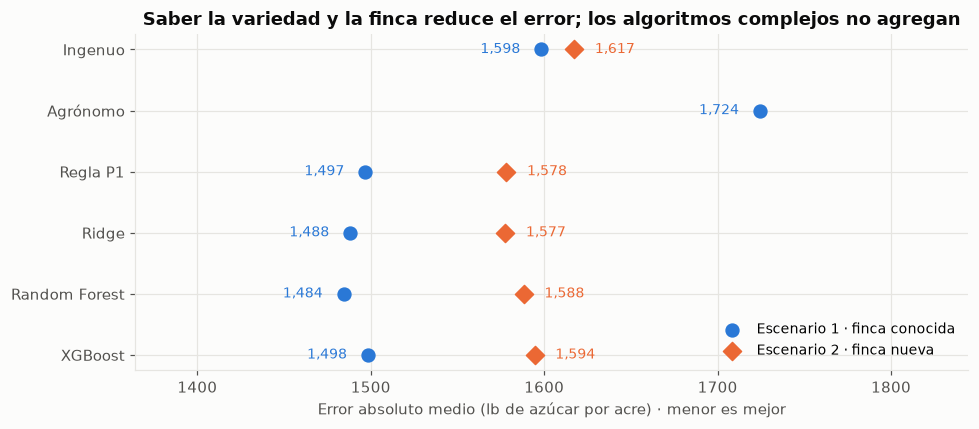

In [13]:
fig, ax = plt.subplots(figsize=(9, 4))
nombres = ORDEN
y = np.arange(len(nombres))
ax.scatter(M1.loc[nombres, "MAE"], y, s=70, color=AZUL, zorder=3, label="Escenario 1 · finca conocida")
m2 = M2.reindex(nombres)["MAE"]
ax.scatter(m2, y, s=70, color=NARANJA, zorder=3, marker="D", label="Escenario 2 · finca nueva")
for i, n in enumerate(nombres):
    ax.text(M1.loc[n, "MAE"] - 12, i, f"{M1.loc[n, 'MAE']:,.0f}", ha="right", va="center", fontsize=9, color=AZUL)
    if not np.isnan(m2[n]):
        ax.text(m2[n] + 12, i, f"{m2[n]:,.0f}", ha="left", va="center", fontsize=9, color=NARANJA)
ax.set_yticks(y, nombres); ax.invert_yaxis()
ax.set_xlabel("Error absoluto medio (lb de azúcar por acre) · menor es mejor")
ax.set_title("Saber la variedad y la finca reduce el error; los algoritmos complejos no agregan")
ax.legend(loc="lower right", frameon=False, fontsize=9)
lo_, hi_ = np.nanmin([M1["MAE"].min(), M2["MAE"].min()]), np.nanmax([M1["MAE"].max(), M2["MAE"].max()])
ax.set_xlim(lo_ - 120, hi_ + 120)
guardar(fig, "serie1_15_comparacion_modelos.png")

## 7. Qué parte del error es predecible (hallazgo)

Se parte el error de Ridge (escenario 1, en log) en dos: lo que comparten todas las parcelas del mismo lote y año
(**error de nivel**: clima, manejo, plagas de esa finca ese año) y lo que es propio de cada variedad (**error de
ventaja**).

In [14]:
r = np.log(E1["T_SPACRE"]) - E1["pred_Ridge"]
def otros(r, g):
    """Error promedio de las OTRAS parcelas del mismo grupo (sin la propia, para no contarla dos veces)."""
    s, c = r.groupby(g).transform("sum"), r.groupby(g).transform("count")
    return ((s - r) / (c - 1)).where(c > 1)
r_lote = otros(r, E1["GRUPO"]); ok = r_lote.notna()
parte_nivel = float((r[ok] * r_lote[ok]).mean() / (r[ok]**2).mean())   # correlación intraclase
r_finca = otros(r, E1["ENV"]); okf = r_finca.notna()
parte_finca = float((r[okf] * r_finca[okf]).mean() / (r[okf]**2).mean())
print(f"Del error cuadrático de Ridge: {parte_nivel:.0%} lo comparten todas las parcelas del mismo lote y año (nivel) "
      f"y {1 - parte_nivel:.0%} es propio de cada variedad (ventaja).")
print(f"   De ese nivel, lo que comparte la finca completa ese año: {parte_finca:.0%} del error total")
oraculo = E1[ok].assign(p=E1["pred_Ridge"][ok] + r_lote[ok])
print(f"Si antes de la zafra se supiera cómo le irá a cada lote (oráculo, no existe): R² {metricas(oraculo, 'p')['R2']:.2f} "
      f"y MAE {metricas(oraculo, 'p')['MAE']:,.0f} lb/acre (vs {M1.loc['Ridge', 'R2']:.2f} y {M1.loc['Ridge', 'MAE']:,.0f})")

anual = E1.assign(err=np.exp(r) - 1).groupby("YEAR").agg(
    sesgo_medio=("err", "median"), error_abs_mediano=("err", lambda x: x.abs().median()))
display((anual * 100).round(1).rename(columns=lambda c: c + " %"))

Del error cuadrático de Ridge: 77% lo comparten todas las parcelas del mismo lote y año (nivel) y 23% es propio de cada variedad (ventaja).
   De ese nivel, lo que comparte la finca completa ese año: 47% del error total


Si antes de la zafra se supiera cómo le irá a cada lote (oráculo, no existe): R² 0.81 y MAE 740 lb/acre (vs 0.28 y 1,488)


,sesgo_medio %,error_abs_mediano %
YEAR,,
2013,5.5,15.7
2014,1.0,13.6
2015,-2.0,13.5
2016,-3.2,17.4
2017,12.1,15.7
2018,9.7,18.5
2019,-16.9,18.3
2020,8.2,17.1
2021,-10.6,18.8


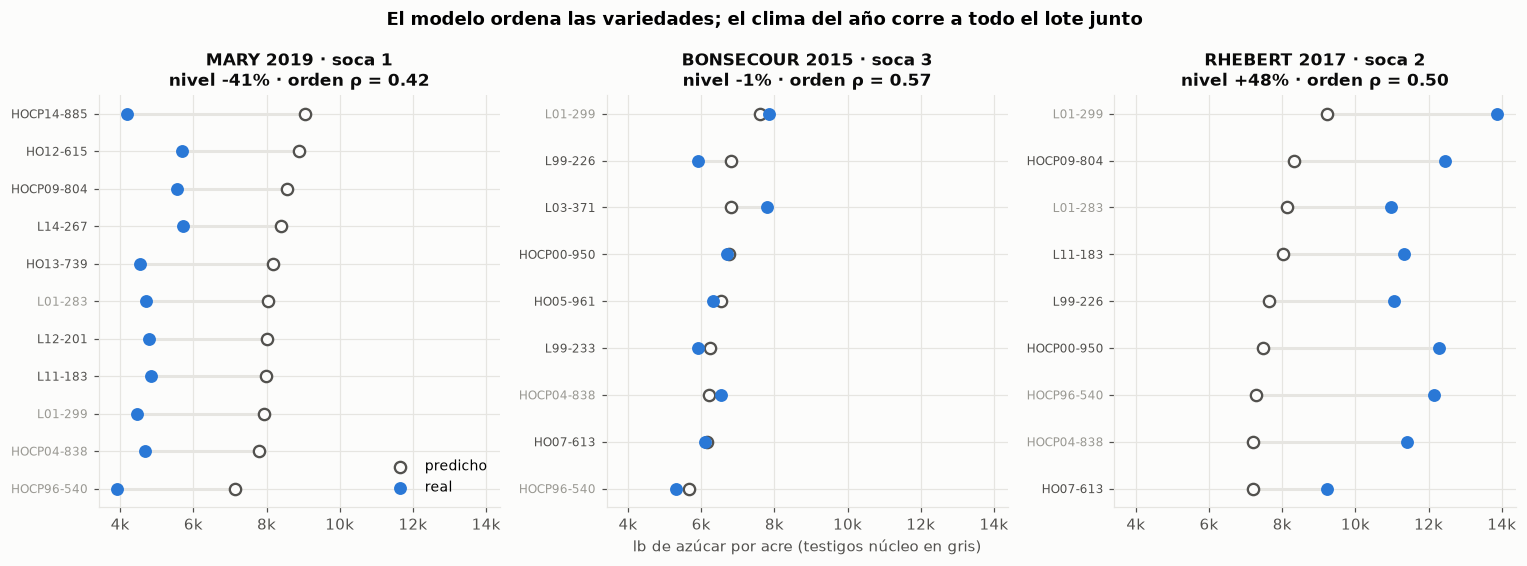

Lotes de ejemplo: ['5|MARY|2018|2019', '5|BONSECOUR|2012|2015', '5|RHEBERT|2015|2017'] | ρ mediano de todos los lotes: 0.49


In [15]:
# Tres lotes reales con un orden de variedades TÍPICO (ρ cercano a la mediana), en un año malo, uno normal y uno bueno
from scipy.stats import spearmanr
g = E1.assign(res=r).groupby("GRUPO").agg(n=("res", "size"), nivel=("res", "mean"), YEAR=("YEAR", "first"),
                                          LOC=("LOC", "first"), CROP=("CROP", "first"))
g["rho"] = pd.Series({k: spearmanr(d["T_SPACRE"], d["pred_Ridge"])[0] for k, d in E1.groupby("GRUPO")})
med = g["rho"].median()
cand = g[g["n"].between(8, 14) & g["rho"].between(med - 0.15, med + 0.15)]
elegidos = [cand[cand["YEAR"] == 2019]["nivel"].idxmin(),
            cand[cand["YEAR"].isin([2014, 2015])]["nivel"].abs().idxmin(),
            cand[cand["YEAR"].isin([2017, 2018])]["nivel"].idxmax()]
NOMBRE_CORTE = {0: "plantía", 1: "soca 1", 2: "soca 2", 3: "soca 3", 4: "soca 4"}
fig, axes = plt.subplots(1, 3, figsize=(14, 5.2), sharex=True)
for ax, k in zip(axes, elegidos):
    d = E1[E1["GRUPO"] == k].assign(pred=lambda x: np.exp(x["pred_Ridge"])).sort_values("pred")
    yy = np.arange(len(d))
    ax.hlines(yy, d["pred"], d["T_SPACRE"], color=REJILLA, lw=2, zorder=1)
    ax.scatter(d["pred"], yy, s=55, facecolor="#fcfcfb", edgecolor=TINTA2, lw=1.5, zorder=2, label="predicho")
    ax.scatter(d["T_SPACRE"], yy, s=55, color=AZUL, zorder=3, label="real")
    ax.set_yticks(yy, d["CLONE"], fontsize=8)
    for t_, c in zip(ax.get_yticklabels(), d["CLONE"]):
        if c in CORE_CHECKS: t_.set_color(GRIS)
    gi = g.loc[k]
    ax.set_title(f"{gi['LOC']} {gi['YEAR']} · {NOMBRE_CORTE[gi['CROP']]}\nnivel {np.exp(gi['nivel']) - 1:+.0%} · orden ρ = {gi['rho']:.2f}",
                 fontsize=11)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))
axes[0].legend(loc="lower right", frameon=False, fontsize=9)
axes[1].set_xlabel("lb de azúcar por acre (testigos núcleo en gris)")
fig.suptitle("El modelo ordena las variedades; el clima del año corre a todo el lote junto", fontweight="bold", fontsize=12)
guardar(fig, "serie1_16_tres_lotes.png")
print("Lotes de ejemplo:", elegidos, f"| ρ mediano de todos los lotes: {med:.2f}")

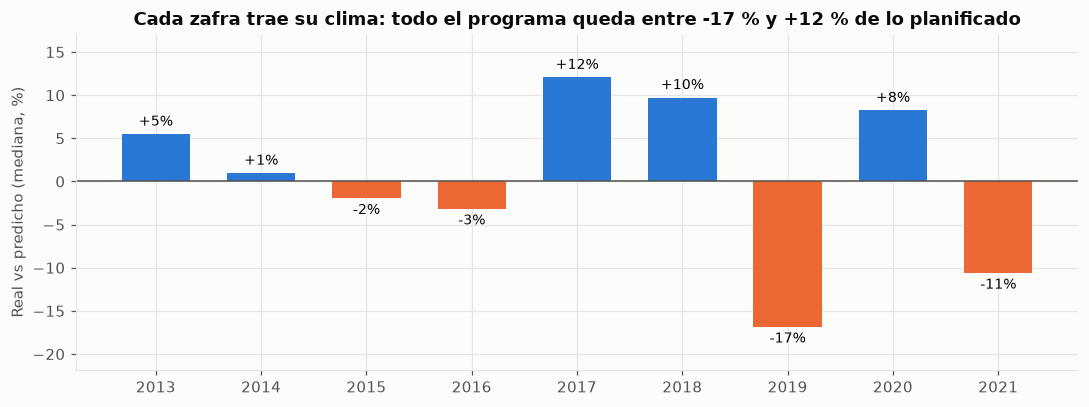

In [16]:
fig, ax = plt.subplots(figsize=(10, 3.8))
a = anual["sesgo_medio"] * 100
ax.bar(a.index, a.values, color=[NARANJA if v < 0 else AZUL for v in a.values], width=0.65)
for x, v in a.items():
    ax.text(x, v + (0.6 if v >= 0 else -0.6), f"{v:+.0f}%", ha="center", va="bottom" if v >= 0 else "top", fontsize=9)
ax.axhline(0, color=TINTA2, lw=1)
ax.set_xticks(a.index); ax.set_ylabel("Real vs predicho (mediana, %)")
ax.set_title(f"Cada zafra trae su clima: todo el programa queda entre {a.min():+.0f} % y {a.max():+.0f} % de lo planificado")
ax.set_ylim(min(a.min() - 5, -5), max(a.max() + 5, 5))
guardar(fig, "serie1_17_error_por_zafra.png")

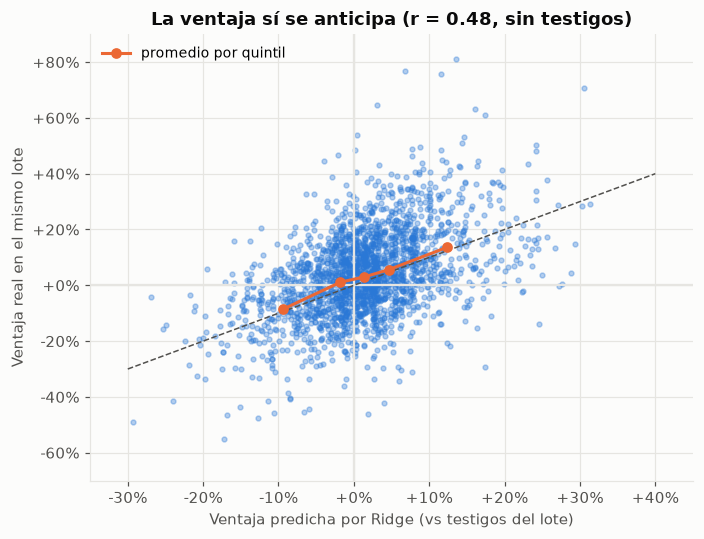

In [17]:
dv = E1[E1["y_rel"].notna() & ~E1["CLONE"].isin(CORE_CHECKS)]
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.scatter(np.exp(dv["rel_Ridge"]) - 1, np.exp(dv["y_rel"]) - 1, s=10, color=AZUL, alpha=0.35)
ax.axhline(0, color=REJILLA, lw=1.5); ax.axvline(0, color=REJILLA, lw=1.5)
ax.plot([-0.3, 0.4], [-0.3, 0.4], color=TINTA2, lw=1, ls="--")
cuartil = pd.qcut(dv["rel_Ridge"], 5)
medias = dv.groupby(cuartil, observed=True).agg(x=("rel_Ridge", "mean"), y=("y_rel", "mean"))
ax.plot(np.exp(medias["x"]) - 1, np.exp(medias["y"]) - 1, color=NARANJA, marker="o", lw=2, label="promedio por quintil")
ax.set_xlim(-0.35, 0.45); ax.set_ylim(-0.7, 0.9)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.0%}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.0%}"))
ax.set_xlabel("Ventaja predicha por Ridge (vs testigos del lote)"); ax.set_ylabel("Ventaja real en el mismo lote")
ax.set_title(f"La ventaja sí se anticipa (r = {np.corrcoef(dv['rel_Ridge'], dv['y_rel'])[0, 1]:.2f}, sin testigos)")
ax.legend(loc="upper left", frameon=False, fontsize=9)
guardar(fig, "serie1_18_ventaja.png")

**Lectura.** Tres cuartas partes del error son de **nivel**: todas las variedades del lote suben o bajan juntas por el
clima, el suelo y el manejo de ese lote ese año (cerca de la mitad lo comparte toda la finca; el resto es propio de cada
lote). Ese error no lo arregla ningún algoritmo con estos datos: no hay ni una columna de clima ni de manejo. El cuarto
restante (la **ventaja** de una variedad sobre otra) es el que importa para decidir **qué sembrar**, y es justo la parte
que el modelo sí predice.

Por eso este modelo sirve para **comparar opciones y presupuestar con una banda**, no para prometer una cifra exacta
para la zafra. Para mejorar el nivel hace falta lo que la pregunta 4 propone capturar: lluvia, temperatura, fecha de
corte y manejo por lote.

## 8. Modelo elegido: Ridge en dos piezas

Ridge queda primero o empatado en error total y orden de variedades, y ningún algoritmo lo supera de forma
significativa. Frente a la regla P1 gana en socas (porque usa el lote anterior); en plantía y en finca nueva la regla es
igual o un poco mejor, porque Ridge aprende un peso prudente para la historia de la variedad (0.62) con años en los que
esa historia era corta. Se explica con 3 números.
Se reentrena con **todas** las filas 2011-2021 para planificar 2022. Para los intervalos de los coeficientes se usa la
misma regresión con errores agrupados por finca-año (las parcelas del mismo lote no son independientes).

In [18]:
A1f = A1[A1["y_rel"].notna()]
ridge1 = Ridge(alpha=1.0).fit(A1f[RIDGE_E1], A1f["y_rel"])
ols1 = smf.ols("y_rel ~ var_rel + lote_ant_rel + tiene_lote_ant", A1f).fit(cov_type="cluster", cov_kwds={"groups": A1f["ENV"]})
coef = pd.DataFrame({"Ridge": np.r_[ridge1.intercept_, ridge1.coef_], "MCO": ols1.params.values,
                     "IC95 bajo": ols1.conf_int()[0].values, "IC95 alto": ols1.conf_int()[1].values},
                    index=["constante"] + RIDGE_E1)
display(coef.round(3))
print(f"Diferencia máxima Ridge vs MCO: {np.abs(coef['Ridge'] - coef['MCO']).max():.4f} (α = 1 es despreciable)")

A2 = tabla_asof(P, ANIOS, escenario=2); A2 = A2[A2["var_conocida"] & A2["y_rel"].notna()]
ridge2 = Ridge(alpha=1.0).fit(A2[RIDGE_E2], A2["y_rel"])
print(f"Escenario 2 (finca nueva): ventaja = {ridge2.intercept_:.3f} + {ridge2.coef_[0]:.3f} × var_rel")

,Ridge,MCO,IC95 bajo,IC95 alto
constante,0.003,0.002,-0.007,0.011
var_rel,0.619,0.635,0.539,0.731
lote_ant_rel,0.491,0.492,0.434,0.551
tiene_lote_ant,-0.015,-0.015,-0.025,-0.004


Diferencia máxima Ridge vs MCO: 0.0159 (α = 1 es despreciable)


Escenario 2 (finca nueva): ventaja = -0.007 + 0.932 × var_rel


In [19]:
b = dict(zip(RIDGE_E1, ridge1.coef_))
print("En palabras (escenario 1):")
print(f"  · Si la historia dice que la variedad rinde 10 % más que los testigos, se espera "
      f"≈ {np.exp(b['var_rel'] * np.log(1.10)) - 1:+.1%} (se le cree {b['var_rel']:.0%} a la historia).")
print(f"  · Si además el año pasado, en ESTE lote, rindió 10 % más que los testigos del lote: "
      f"≈ {np.exp(b['lote_ant_rel'] * np.log(1.10)) - 1:+.1%} adicional.")
print(f"  · Lo que dio el lote completo el año pasado (clima) no entra: no se repite.")

# Coherencia con los árboles: importancia por permutación del Random Forest (escenario 1, datos 2019-2021 fuera)
rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=20, max_features=0.5, n_jobs=-1, random_state=SEED)
tr, te = A1f[A1f["YEAR"] < 2019], A1f[A1f["YEAR"] >= 2019]
rf.fit(tr[TREE_E1], tr["y_rel"])
imp = permutation_importance(rf, te[TREE_E1], te["y_rel"], n_repeats=10, random_state=SEED, scoring="neg_mean_absolute_error")
IMP = pd.Series(imp.importances_mean * 100, index=TREE_E1).sort_values(ascending=False)
print("\nRandom Forest · aumento del error de ventaja al desordenar cada variable (pp):"); print(IMP.round(2).to_string())

En palabras (escenario 1):
  · Si la historia dice que la variedad rinde 10 % más que los testigos, se espera ≈ +6.1% (se le cree 62% a la historia).
  · Si además el año pasado, en ESTE lote, rindió 10 % más que los testigos del lote: ≈ +4.8% adicional.
  · Lo que dio el lote completo el año pasado (clima) no entra: no se repite.



Random Forest · aumento del error de ventaja al desordenar cada variable (pp):
var_rel           1.80
lote_ant_rel      1.62
corte             0.06
var_n             0.05
lote_ant_amb      0.03
tiene_lote_ant    0.02
loc_rel           0.01


In [20]:
# Banda de 80 %: para la zafra t se usan los errores que el modelo cometió en las zafras ANTERIORES a t
# (no los del entrenamiento, que son optimistas). ¿Contiene al valor real 8 de cada 10 veces?
cob, BANDA, por_zafra = [], {}, {}
for nombre, E in [("Escenario 1", E1), ("Escenario 2", E2)]:
    res = np.log(E["T_SPACRE"]) - E["pred_Ridge"]
    partes_cob = []
    for t in PRUEBA[1:]:
        q10, q90 = np.quantile(res[E["YEAR"] < t], [0.10, 0.90])
        m = E["YEAR"] == t
        partes_cob.append(pd.DataFrame({"ok": (res[m] >= q10) & (res[m] <= q90), "CROP": E.loc[m, "CROP"],
                                        "YEAR": t, "ancho": np.exp(q90) - np.exp(q10)}))
    dentro = pd.concat(partes_cob)
    por_zafra[nombre] = dentro.groupby("YEAR")["ok"].mean()
    BANDA[nombre] = np.quantile(res, [0.10, 0.90])          # banda para 2022: todos los errores 2013-2021
    cob.append({"escenario": nombre, "cobertura banda 80 %": dentro["ok"].mean(), "ancho (% del predicho)": dentro["ancho"].median(),
                "cobertura plantía": dentro.loc[dentro["CROP"] == 0, "ok"].mean(),
                "cobertura socas": dentro.loc[dentro["CROP"] > 0, "ok"].mean(),
                "banda 2022": f"{np.exp(BANDA[nombre][0]) - 1:+.0%} / {np.exp(BANDA[nombre][1]) - 1:+.0%}"})
COB = pd.DataFrame(cob).set_index("escenario"); display(COB.round(3))
print("Cobertura por zafra (escenario 1):", por_zafra["Escenario 1"].round(2).to_dict())

,cobertura banda 80 %,ancho (% del predicho),cobertura plantía,cobertura socas,banda 2022
escenario,,,,,
Escenario 1,0.736,0.569,0.774,0.723,-29% / +32%
Escenario 2,0.714,0.574,0.772,0.692,-32% / +33%


Cobertura por zafra (escenario 1): {2014: 0.85, 2015: 0.87, 2016: 0.67, 2017: 0.75, 2018: 0.7, 2019: 0.63, 2020: 0.78, 2021: 0.66}


**Lectura de la banda.** Calculada con los errores de zafras anteriores, la banda "de 80 %" cubrió ~3 de cada 4 casos:
las zafras recientes (2019, 2021) fueron más variables que las anteriores. Para presupuestar se recomienda leerla como
una banda de ~75 %, o ampliarla si la Gerencia necesita 80 % real. Es ancha (±30 %) porque incluye el clima del año.

## 9. Para la siguiente zafra: pronóstico 2022 y artefacto para la API

Dos usos concretos:
1. **Lotes en pie**: cada lote de etapa 5 cosechado en 2021 (hasta soca 3) da su siguiente corte en 2022.
2. **Siembras nuevas**: plantía esperada de las 3 variedades recomendadas en la pregunta 1 en cada finca.

In [21]:
H22 = historia(P, 2022)
q10_1, q90_1 = BANDA["Escenario 1"]

# 1) Lotes en pie: el corte k de 2021 pasa a k+1 en 2022
u = P[(P["YEAR"] == 2021) & (P["CROP"] < 4)].copy()
core21 = u[u["CLONE"].isin(CORE_CHECKS)].groupby("TRIAL")["T_SPACRE"].apply(lambda x: np.log(x).mean())
nx = u[["TRIAL", "LOC", "CLONE", "CROP", "rel_sugar", "T_SPACRE"]].rename(columns={"rel_sugar": "rel_ant", "T_SPACRE": "y_ant"})
nx["CROP"] += 1; nx["YEAR"] = 2022; nx["lote_core_log"] = nx["TRIAL"].map(core21)
fx = variables(nx, H22, 1)
nx["pred"] = np.exp(fx["base_corte"] + fx["loc_rel"] + ridge1.predict(fx[RIDGE_E1]))
nx["p10"], nx["p90"] = nx["pred"] * np.exp(q10_1), nx["pred"] * np.exp(q90_1)
nx["var_conocida"] = fx["var_conocida"]
PRON = nx[nx["var_conocida"]][["LOC", "TRIAL", "CLONE", "CROP", "y_ant", "rel_ant", "pred", "p10", "p90"]].rename(
    columns={"CROP": "corte_2022", "y_ant": "real_2021", "rel_ant": "ventaja_2021"}).sort_values(["LOC", "corte_2022", "pred"], ascending=[True, True, False])
PRON.round({"real_2021": 0, "ventaja_2021": 4, "pred": 0, "p10": 0, "p90": 0}).to_csv(TAB / "serie1_pronostico_2022_lotes.csv", index=False)
print(f"{len(PRON)} lotes-variedad en pie para 2022 ({PRON['LOC'].nunique()} fincas). Ejemplo:")
display(PRON.head(8).round(0))

467 lotes-variedad en pie para 2022 (12 fincas). Ejemplo:


,LOC,TRIAL,CLONE,corte_2022,real_2021,ventaja_2021,pred,p10,p90
387,ALLAINS,5|ALLAINS|2021,HOCP14-885,1,9752.0,1.0,9605.0,6779.0,12688.0
389,ALLAINS,5|ALLAINS|2021,HOL15-508,1,9069.0,1.0,9070.0,6401.0,11980.0
383,ALLAINS,5|ALLAINS|2021,HO12-615,1,8933.0,1.0,8798.0,6209.0,11621.0
392,ALLAINS,5|ALLAINS|2021,L14-267,1,8201.0,1.0,8428.0,5948.0,11132.0
390,ALLAINS,5|ALLAINS|2021,L01-299,1,7678.0,NaN,8250.0,5823.0,10898.0
393,ALLAINS,5|ALLAINS|2021,L15-306,1,7571.0,1.0,8227.0,5806.0,10867.0
388,ALLAINS,5|ALLAINS|2021,HOCP17-701,1,8539.0,1.0,8122.0,5732.0,10729.0
391,ALLAINS,5|ALLAINS|2021,L12-201,1,7739.0,1.0,7820.0,5519.0,10329.0


In [22]:
# 2) Siembras nuevas 2022: plantía esperada de las 3 recomendadas (pregunta 1) vs el testigo promedio, por finca
top3 = pd.read_csv(TAB / "serie1_recomendacion.csv")["CLONE"].head(3).tolist()
fincas = sorted(H22["loc"].index)
grid = pd.DataFrame([(c, L) for c in top3 + CORE_CHECKS for L in fincas], columns=["CLONE", "LOC"])
grid["CROP"] = 0; grid["YEAR"] = 2022
for col in ["rel_ant", "y_ant", "lote_core_log"]: grid[col] = np.nan
fg = variables(grid, H22, 1)
grid["pred"] = np.exp(fg["base_corte"] + fg["loc_rel"] + ridge1.predict(fg[RIDGE_E1]))
tabla_pl = grid.pivot_table(index="LOC", columns="CLONE", values="pred")
tabla_pl["testigo promedio"] = tabla_pl[CORE_CHECKS].mean(axis=1)
tabla_pl = tabla_pl[top3 + ["testigo promedio"]].sort_values("testigo promedio", ascending=False)
tabla_pl.round(0).to_csv(TAB / "serie1_pronostico_2022_plantia.csv")
display(tabla_pl.round(0))
print(f"Banda 80 % para cada valor: {np.exp(q10_1)-1:+.0%} / {np.exp(q90_1)-1:+.0%}")

CLONE,HOCP14-885,HOL15-508,L15-306,testigo promedio
LOC,,,,
RHEBERT,11098.0,10554.0,10507.0,10062.0
GLENWOOD,10454.0,9942.0,9898.0,9479.0
LANDRY,10337.0,9831.0,9787.0,9373.0
STJOHN,10045.0,9553.0,9510.0,9108.0
LANAUX,9840.0,9359.0,9317.0,8922.0
BONSECOUR,9745.0,9268.0,9227.0,8836.0
HARPER,9528.0,9062.0,9021.0,8639.0
DOMINGUE,9231.0,8779.0,8740.0,8370.0
ALLAINS,9185.0,8735.0,8696.0,8328.0


Banda 80 % para cada valor: -29% / +32%


In [23]:
# Artefacto: todo lo que la API necesita para predecir sin re-entrenar (JSON legible, sin pickles)
q10_2, q90_2 = BANDA["Escenario 2"]
modelo = {
    "descripcion": "Serie I · P2. log(lb azúcar/acre) = nivel (base_corte + loc_rel) + ventaja (Ridge). Entrenado con etapa 5, 2011-2021.",
    "planifica_zafra": 2022,
    "encogimiento": {"lambda_a": LAMBDA_A, "lambda_b": LAMBDA_B, "lambda_loc": LAMBDA_LOC},
    "testigos_nucleo": CORE_CHECKS,
    "escenario_1": {"variables": RIDGE_E1, "constante": float(ridge1.intercept_), "coef": dict(zip(RIDGE_E1, map(float, ridge1.coef_))),
                    "banda80_log": [float(q10_1), float(q90_1)]},
    "escenario_2": {"variables": RIDGE_E2, "constante": float(ridge2.intercept_), "coef": dict(zip(RIDGE_E2, map(float, ridge2.coef_))),
                    "banda80_log": [float(q10_2), float(q90_2)]},
    "base_corte_log": {int(k): float(v) for k, v in H22["base"].items()},
    "fincas_loc_rel": {k: float(v) for k, v in H22["loc"]["loc_rel"].items()},
    "variedades": {c: {"a": float(r.a), "b": float(r.b), "kmax": int(r.kmax), "n": int(r.n)} for c, r in H22["var"].iterrows()},
    "validacion": {"escenario_1": M1.loc["Ridge"].to_dict(), "escenario_2": M2.loc["Ridge"].to_dict(),
                   "cobertura_banda80": COB["cobertura banda 80 %"].to_dict()},
}
(MOD / "serie1_modelo_p2.json").write_text(json.dumps(modelo, indent=1, ensure_ascii=False), encoding="utf-8")

# Verificación: el JSON reproduce las predicciones del notebook
mj = json.loads((MOD / "serie1_modelo_p2.json").read_text(encoding="utf-8"))
def predecir_json(clone, loc, corte, rel_ant=None):
    v = mj["variedades"].get(clone); c1 = mj["escenario_1"]
    var_rel = 0.0 if v is None else v["a"] + v["b"] * min(corte, v["kmax"])
    lote = 0.0 if rel_ant is None else np.log(rel_ant)
    rel = c1["constante"] + c1["coef"]["var_rel"] * var_rel + c1["coef"]["lote_ant_rel"] * lote + c1["coef"]["tiene_lote_ant"] * (rel_ant is not None)
    return float(np.exp(mj["base_corte_log"][str(corte)] + mj["fincas_loc_rel"].get(loc, 0.0) + rel))
chk = [predecir_json(r.CLONE, r.LOC, 0) / r.pred - 1 for r in grid.itertuples()]
print(f"JSON vs notebook (plantía, {len(chk)} casos): diferencia máxima {np.max(np.abs(chk)):.2e}")

pd.concat({"escenario_1": M1, "escenario_2": M2}).to_csv(TAB / "serie1_p2_metricas.csv")
COMP1.to_csv(TAB / "serie1_p2_comparaciones.csv")
resumen = {"metricas_e1": M1.round(4).to_dict("index"), "metricas_e2": M2.round(4).to_dict("index"),
           "parte_error_nivel": parte_nivel, "parte_error_finca": parte_finca, "error_por_zafra_pct": {str(k): float(v) for k, v in (anual["sesgo_medio"] * 100).round(3).items()},
           "coef_e1": coef.round(4).to_dict("index"), "cobertura": COB.round(4).to_dict("index"),
           "costo_finca_nueva_lb": costo_finca, "costo_finca_ic90": [lo, hi], "plantia_2022": tabla_pl.round(0).to_dict("index"),
           "por_corte": {f"{t}|{m}": r.round(4).to_dict() for (t, m), r in pc[["MAE", "R2", "orden_spearman", "R2_ventaja"]].iterrows()},
           "diagnostico_directo": {"mae_regla": metricas(D, "pred_regla")["MAE"], "mae_directo": metricas(D, "p_directo")["MAE"],
                                   "por_anio": {str(k): r.round(4).to_dict() for k, r in diag.iterrows()}},
           "comparaciones": {k: r.round(3).to_dict() for k, r in COMP1.iterrows()},
           "cobertura_por_zafra": {str(k): float(v) for k, v in por_zafra["Escenario 1"].round(4).items()},
           "lotes_ejemplo": elegidos, "rho_mediano_lotes": float(med), "importancia_rf_pp": IMP.round(3).to_dict(),
           "efecto_anio_autocorr": float(np.corrcoef(efecto_anio[:-1], efecto_anio[1:])[0, 1])}
(MOD / "serie1_resumen_p2.json").write_text(json.dumps(resumen, indent=1, ensure_ascii=False, default=float), encoding="utf-8")
cols_v = ["LOC", "TRIAL", "CLONE", "CROP", "YEAR", "T_SPACRE"]
val = pd.concat({
    "1": E1[cols_v].assign(**{n: np.exp(E1[f"pred_{n}"]) for n in ["Ridge", "Regla P1", "Ingenuo"]}),
    "2": E2[cols_v].assign(**{n: np.exp(E2[f"pred_{n}"]) for n in ["Ridge", "Regla P1", "Ingenuo"]}),
}, names=["escenario"]).reset_index(level=0)
val.round(1).to_csv(TAB / "serie1_p2_validacion.csv", index=False)
print("Guardado: modelo, métricas, comparaciones, pronósticos 2022 y resumen")

JSON vs notebook (plantía, 98 casos): diferencia máxima 0.00e+00


Guardado: modelo, métricas, comparaciones, pronósticos 2022 y resumen


## 10. Evaluación gerencial

In [24]:
r1, r2 = M1.loc["Ridge"], M2.loc["Ridge"]
print(f"Escenario 1 (finca conocida): error típico {r1['MAPE_%']:.0f} % por parcela (MAE {r1['MAE']:,.0f} lb/acre), "
      f"orden de variedades dentro del lote ρ = {r1['orden_spearman']:.2f}")
print(f"Escenario 2 (finca nueva):    error típico {r2['MAPE_%']:.0f} % (MAE {r2['MAE']:,.0f} lb/acre), ρ = {r2['orden_spearman']:.2f}")
print(f"Ingenuo (promedio histórico): error típico {M1.loc['Ingenuo', 'MAPE_%']:.0f} %")
print(f"Banda 80 %: cubre {COB.loc['Escenario 1', 'cobertura banda 80 %']:.0%} (esc. 1) y "
      f"{COB.loc['Escenario 2', 'cobertura banda 80 %']:.0%} (esc. 2) de los casos reales")
print(f"Parte del error que es clima/manejo del lote-año: {parte_nivel:.0%}")

Escenario 1 (finca conocida): error típico 22 % por parcela (MAE 1,488 lb/acre), orden de variedades dentro del lote ρ = 0.44
Escenario 2 (finca nueva):    error típico 24 % (MAE 1,577 lb/acre), ρ = 0.39
Ingenuo (promedio histórico): error típico 24 %
Banda 80 %: cubre 74% (esc. 1) y 71% (esc. 2) de los casos reales
Parte del error que es clima/manejo del lote-año: 77%


**Qué significa para el ingenio.** Se puede estimar el azúcar por acre de una variedad en una finca con un error típico
de ~22 % por parcela (una variedad en una finca y zafra), y ordenar las variedades dentro de un mismo lote razonablemente bien. Tres cuartas partes del error
son lo que le pasa a todo el lote ese año (clima, suelo, manejo), que no se puede anticipar con estos datos. El método de
la pregunta 1 (comparar contra testigos en el mismo lote) es, en sí mismo, casi todo el poder predictivo: un modelo de 3
coeficientes basta.

**Decisión recomendada.**
1. Usar **Ridge en dos piezas** para la planificación: nivel de la finca (historia) + ventaja de la variedad. Es
   explicable en una línea y nadie tiene que confiar en una caja negra.
2. Presupuestar con la **banda** (−29 % / +32 %), no con el punto. En validación cubrió ~3 de cada 4 casos.
3. Para fincas sin historia (escenario 2), usar el modelo de finca nueva y reemplazarlo por el de escenario 1 en cuanto
   exista la primera cosecha de la finca.
4. No invertir en modelos más complejos con estos datos: Random Forest y XGBoost no mejoraron. La siguiente mejora
   vendrá de **datos nuevos** (clima y manejo por lote, pregunta 4), no de algoritmos.

**Impacto estimado.** Frente a planificar con el promedio histórico, el error por parcela baja de ~24 % a ~22 %
(−100 lb/acre, IC90 −175 a −29) y, sobre todo, el modelo **distingue variedades**: el promedio histórico da el mismo
número para todas, el modelo las ordena dentro de cada lote con ρ = 0.44 (0.51 en socas). El valor está en decidir qué
variedad va en qué finca, no en adivinar la zafra total.

**Riesgos.**
- *Clima:* un año como 2019 o 2021 deja todo el programa 11-17 % abajo de lo planificado. El modelo no lo anticipa.
- *Validez externa:* entrenado en Louisiana. Para el ingenio se traslada la estructura (nivel + ventaja vs testigos),
  no los números: hay que recalibrar con 2-3 zafras propias.
- *Variedades con poca historia:* el encogimiento las acerca a los testigos; su predicción es prudente por diseño.

**Nivel de certeza.** Alta en que el método supera al promedio histórico y en que los modelos complejos no agregan (las
diferencias tienen intervalos por bootstrap de fincas-año). Media en la cifra puntual de cada lote: por eso se entrega
con banda.